> Notebook-friendly copy of `part-III/6.2-deep-computer-vision-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

In [1]:
# --- environment setup (generated, not part of the lesson) ---
# Colab and Kaggle do not ship every package this notebook imports.
# This is a no-op in an environment that is already set up.
import importlib.util
import subprocess
import sys

for module, package in {"pooch": "pooch", "torchmetrics": "torchmetrics"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# 6.2) (Exercise) Deep Computer Vision

<center>
<img width=60% src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.2-shinkyo-style-transfer.jpg?raw=1'>

Style transfer applied to a picture of Shinkyo Bridge in Nikko (日光の神橋), using Google's [Deep Dream Generator](https://deepdreamgenerator.com/)
</center>

Convolutional networks find spatial relationships in multidimensional data (most often images), which allow computers to detect patterns to make predictions or modify the input images in surprising ways. The following image shows a series of feature map visualizations for a convolutional neural network, extracted from a picture of a cat: features related to the eyes, ears, or details as fine as pupil types.

<center> <img width=80% src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.2-cat-feature-maps.png?raw=1'> </center>

For the style transfer example shown above, the original image is transformed so that it looks similar to a target style image until they're virtually indistinguishable using the information from the filters:

<center> <img width=80% src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.2-style-transfer-mechanism.png?raw=1'> </center>

**🎯 Learning objectives**

- Train a convolutional neural network (CNN) to classify flower species from photos, with and without data augmentation
- Train, validate and test the CNN, and log the results in TensorBoard

Convolution Visualization images from:
Qin, Z., Yu, F., Liu, C., & Chen, X. (2018). How convolutional neural network see the world-A survey of convolutional neural network visualization methods. [*arXiv preprint arXiv:1804.11191*](https://arxiv.org/pdf/1804.11191.pdf?ref=https://githubhelp.com).

## Notebook Setup

Today we'll be training CNNs, a process which can be very slow when run on a CPU. Instead, we'll be relying on GPU processing! Thankfully, we can easily make the switch on Colab!

(If you're running the notebooks on your own computer, you *may* have to jump through a few hoops in order to take advantage of your computer's GPU)

***Do note, however, that access to GPUs on Colab is somewhat limited - running your model's training too many times may limit your access to the GPU resources at Google.***

### Changing the Runtime to GPU on Colab
<center>
<img width=70% src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.2-colab-gpu-runtime-menu.png?raw=1' border=1px><br>Click on the <i>runtime</i> dropdown menu and click on "change runtime type"<br><br>
<img width=45% src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.2-colab-gpu-hardware-accelerator.png?raw=1' border=1px><br>Then select "GPU" on the hardware accelerator dropdown menu<br><br>
</center>

Once you've changed the runtime type, run the Notebook setup cell. A message confirming that you've succesfully changed runtime type should be printed 😃

In the setup cell, let's import a few common modules, ensure MatplotLib plots figures inline and prepare a function to save the figures. We'll also check that Python 3.9 or later is installed, as well as PyTorch ≥2.0 and TorchVision.

In [2]:
import sys

# Is this notebook running on Colab or Kaggle?
IS_COLAB = "google.colab" in sys.modules
IS_KAGGLE = "kaggle_secrets" in sys.modules

import torch
import torch.nn as nn

# TorchVision, to load the flowers dataset and preprocess images
import torchvision
import torchvision.transforms.v2 as T

# To track streaming metrics and log to TensorBoard
import torchmetrics
import torch.utils.tensorboard

if not torch.cuda.is_available() and not torch.backends.mps.is_available():
    print("No GPU was detected. CNNs can be very slow without a GPU.")
    if IS_COLAB:
        print("Go to Runtime > Change runtime and select a GPU hardware accelerator.")
    if IS_KAGGLE:
        print("Go to Settings > Accelerator and select GPU.")
    device = "cpu"
else:
    device = "cuda" if torch.cuda.is_available() else "mps"
    print(f"GPU runtime succesfully selected! We're ready to train our CNNs.")

# Common imports
import numpy as np
import os
import tarfile
import pooch

# to make this notebook's output stable across runs
rnd_seed = 42
rnd_gen = np.random.default_rng(rnd_seed)

# To plot pretty figures
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)

# Where to save the figures
IMAGES_PATH = "_files"
os.makedirs(IMAGES_PATH, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = os.path.join(IMAGES_PATH, fig_id + "." + fig_extension)
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

# Loading Tensorboard
%load_ext tensorboard

GPU runtime succesfully selected! We're ready to train our CNNs.


## Data Setup

Today, we won't be working on the MNIST dataset! Instead, we'll be working on the [tf_flowers dataset](https://knowyourdata-tfds.withgoogle.com/#tab=STATS&dataset=tf_flowers), and we'll be attempting to train a Neural Network to learn to classify the flowers into 1 of 5 flower species: daisies, dandelions, roses, sunflowers, and tulips.

Let's begin by loading the data. It's about two-hundred megabytes, so — to keep this repository's own dataset snapshot under its 50 MB-per-file limit — it's committed here split into six smaller chunks that we'll re-download and reassemble.

In [3]:
# Run this cell
torch.manual_seed(rnd_seed)
np.random.seed(rnd_seed)

## Q1) Load the `flower_photos` dataset. Split it into a training, validation, and test set (75% / 15% / 10%).

*Hint 1: The cell above already reassembles the dataset into a directory of one subfolder per flower species (`flowers_root`) — exactly the layout [`torchvision.datasets.ImageFolder`](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.ImageFolder.html) expects.*

*Hint 2: Once you have the full dataset as an `ImageFolder`, use [`torch.utils.data.random_split()`](https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.random_split) to carve it into three `Subset`s. It takes a list of split sizes (as sample counts, or as fractions that sum to 1) — `[0.75, 0.15, 0.10]` gives you the split we want.*

*Hint 3: `ImageFolder` has a `.classes` attribute with the flower names, in the order used for the integer labels — you'll want to keep a reference to it, since a `Subset` doesn't expose it directly.*

In [4]:
# Run this cell to fetch and reassemble the dataset
chunk_suffixes = ["aa", "ab", "ac", "ad", "ae", "af"]
chunk_hashes = {
    "aa": "a9329cedffae413c3a3e8425e2e414397c9ab74c25bce5b6b85ab63c6982e4da",
    "ab": "e2fe2c5863138111f49adf2d230f542605a8de6d94638bdbe3351aabe391ed2b",
    "ac": "2f21c926f502e7aad06ab212a8d426546c39a2788f2121d9622f953f4d6d27c6",
    "ad": "f145f262789de8af8a25cc802f7f7c45b8fac1a4fff44b77ad2fe1ecbe861971",
    "ae": "6d14aae212c9878706a0c19546bd0bcd3f5852dd7e55de90efe0d83c0516fcde",
    "af": "1b49a09ec97dd3b442d0f6fa8f8f519f00862387895327f14bfc617a3c1e65e8",
}
cache_dir = pooch.os_cache("mlees")
chunk_paths = [
    pooch.retrieve(
        url=f"https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-III/flower_photos.tgz.part{suffix}",
        known_hash=f"sha256:{chunk_hashes[suffix]}",
        fname=f"flower_photos.tgz.part{suffix}",
        path=cache_dir,
    )
    for suffix in chunk_suffixes
]

In [5]:
flowers_archive = os.path.join(cache_dir, "flower_photos.tgz")
if not os.path.exists(flowers_archive):
    with open(flowers_archive, "wb") as out_f:
        for chunk_path in chunk_paths:
            with open(chunk_path, "rb") as in_f:
                out_f.write(in_f.read())
    with tarfile.open(flowers_archive) as tar:
        tar.extractall(cache_dir)  # décompresse l'archive .tgz

/tmp/ipykernel_450/2775173292.py:8: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(cache_dir)  # décompresse l'archive .tgz


In [6]:
flowers_root = os.path.join(cache_dir, "flower_photos")  # dossier contenant 1 sous-dossier par espèce

In [7]:
# ToImage -> tenseur image ; ToDtype(float32, scale=True) -> pixels divisés par 255, donc entre 0 et 1
toTensor = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True)])

# ImageFolder : 1 sous-dossier = 1 classe ; l'étiquette = numéro du dossier (ordre alphabétique)
full_dataset = torchvision.datasets.ImageFolder(root=flowers_root, transform=toTensor)
class_names = full_dataset.classes  # noms des 5 fleurs, dans l'ordre des étiquettes 0-4
print(class_names, len(full_dataset), "images")

torch.manual_seed(rnd_seed)  # graine -> le découpage aléatoire est toujours le même
# random_split découpe en 3 sous-ensembles : 75 % train, 15 % validation, 10 % test
train_set, valid_set, test_set = torch.utils.data.random_split(
    full_dataset, [0.75, 0.15, 0.10])

['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips'] 3670 images


We now have a set of variables that have the training, validation, and test sets, as well as `class_names`. Let's go ahead and define a function that will let us visualize our data.

## Q2) Define a function that takes in a dataset, its name, and the list of class names, prints out how many samples are in the dataset, and displays a set of samples from the dataset.

*Hint 1: `len(dataset)` gives you the number of samples in any PyTorch dataset (or `Subset`).*

*Hint 2: You can use the `rnd_gen.integers()` generator to pick a set of random indices into the dataset, then index the dataset with each one (`dataset[index]` returns an `(image, label)` pair). This is the same pattern as the `sample_plotter` function from the artificial-neural-networks exercises — you can reuse that approach here.*

*Hint 3: A dataset image tensor from `ImageFolder` has shape `(channels, height, width)`, so before calling `plt.imshow()` you'll need to move the channel dimension to the end with `.permute(1, 2, 0)`.*

In [8]:
def dataset_info(dataset, name, class_names, n_rows=3, n_cols=5):
    # Extract and print the number of samples in the dataset
    print(f"{name} set: {len(dataset)} samples")  # len() = nb d'images

    # Pick a set of random indices, plot a grid of the corresponding images and labels
    indices = rnd_gen.integers(0, len(dataset), size=(n_rows, n_cols))  # grille d'indices aléatoires
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 2.5, n_rows * 2.5))
    for (row, col), idx in np.ndenumerate(indices):  # position dans la grille + indice de l'image
        image, label = dataset[idx]  # dataset[i] renvoie (image, étiquette)
        axes[row, col].imshow(image.permute(1, 2, 0))  # (C, H, W) -> (H, W, C) : format attendu par imshow
        axes[row, col].set_title(class_names[label])  # numéro -> nom de la fleur
        axes[row, col].axis('off')
    fig.suptitle(name)
    plt.show()
    return None

And now let's run the function on each of our training, validation, and test sets...

## Q3) Run your defined visualization function on each of the training, validation, and test sets.

Training set: 2753 samples


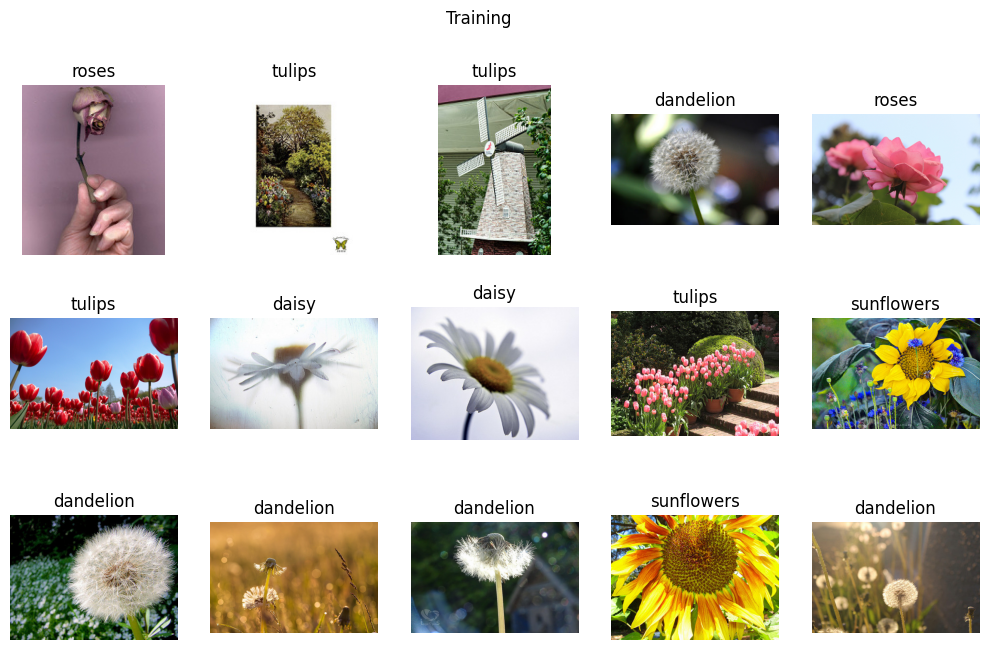

Validation set: 550 samples


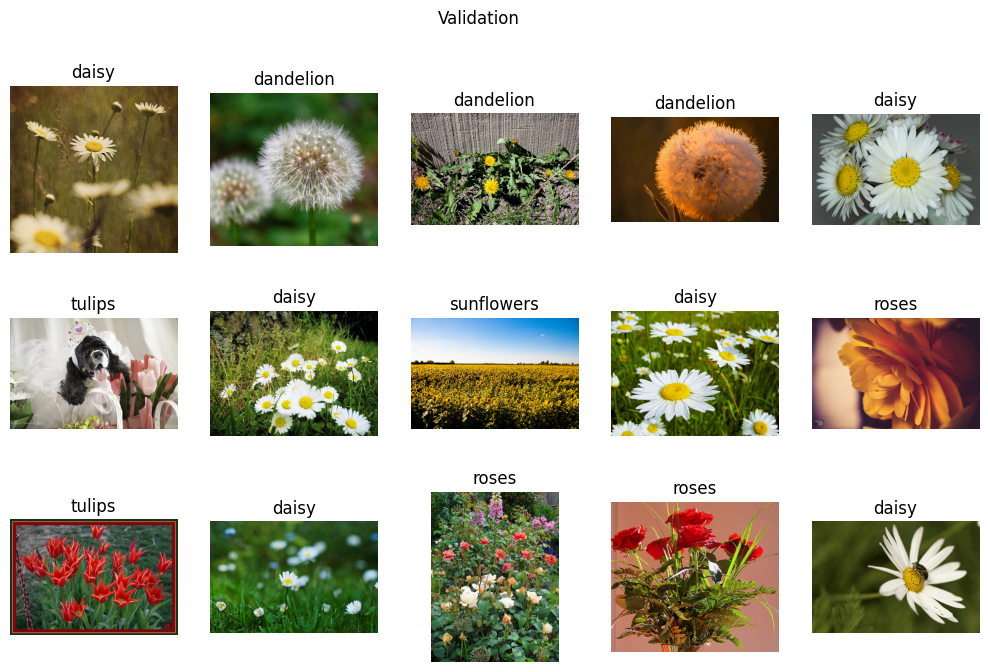

Test set: 367 samples


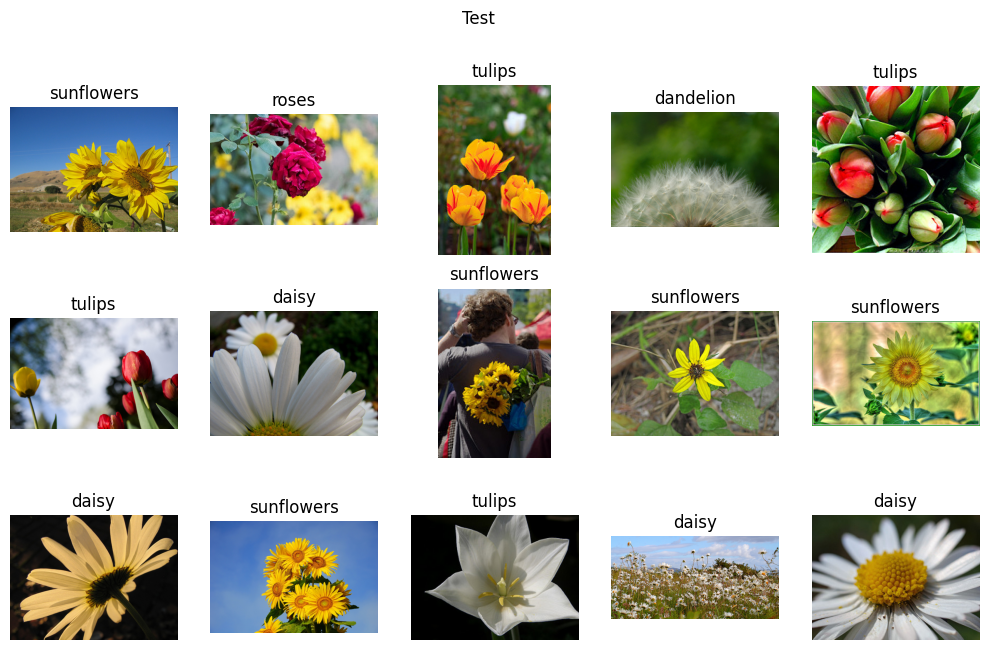

In [9]:
dataset_info(train_set, "Training", class_names)  # aperçu du jeu d'entraînement
dataset_info(valid_set, "Validation", class_names)  # aperçu de la validation
dataset_info(test_set, "Test", class_names)  # aperçu du test

If everything worked out fine, you'll have a grid of nicely labeled flower photos as your output:

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.2-flower-sample-grid-reference.png?raw=1'> </center>

The flowers look very nice! ("*And I'd be pretty bad at classifying them myself...*" - a botanically challenged TA)

However, there is one sore point for our purposes - *the images have different resolutions*. Why is this a sore point? Well, in our architecture we'll eventually flatten our convolutions and connect them to a dense layer, and as such we will need for all of the images to have the same dimensions! (There are other ways to address the issue of resolution, but we won't discuss these for now)

We also note that our `toTensor` transform already scaled the pixel values to fall between 0 and 1 — one fewer thing to worry about compared to the raw 0–255 integers.

Let's write a preprocessing transform that resizes every image to a common size!

## Q4) Write a preprocessing transform that resizes images to 128x128.

*Hint 1: [`torchvision.transforms.v2.Resize((height, width))`](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.v2.Resize.html) resizes an image tensor to a fixed size.*

*Hint 2: You can chain it onto the `toTensor` pipeline from Q1 using `T.Compose([...])`.*

In [10]:
# même pré-traitement qu'en Q1 + Resize : toutes les images en 128x128 (le réseau a besoin d'une taille fixe)
preprocessing_transform = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True), T.Resize((128, 128))])

## Q5) Recreate the dataset (and its train/validation/test split) using the new preprocessing transform.

*Hint 1: `random_split()`'s three-way split isn't affected by which transform the underlying dataset uses — as long as you re-create `full_dataset` with `transform=preprocessing_transform` and re-run `random_split()` with the same seed, you'll get the same three subsets, just resized this time.*

In [11]:
full_dataset = torchvision.datasets.ImageFolder(root=flowers_root, transform=preprocessing_transform)  # même dossier, nouveau pré-traitement

torch.manual_seed(rnd_seed)  # même graine -> exactement le même découpage qu'en Q1
train_set, valid_set, test_set = torch.utils.data.random_split(
    full_dataset, [0.75, 0.15, 0.10])

At this point I'd also like to point out that our dataset is not set up to be taken in batches. If you index a single sample, you'll extract a single (image, label) pair — not a batch of them.

In [12]:
image, label = train_set[0]  # 1 seul échantillon : (image, étiquette)
print(f'Image shape: {image.shape}, Label: {label}')

Image shape: torch.Size([3, 128, 128]), Label: 4


We actually want to work in 32 image batches, so let's go ahead as set up data loaders for our datasets.

## Q6) Wrap each of the training, validation, and test sets in a `DataLoader` with a batch size of 32.

*Hint 1: You can define a `batch_size` variable to guarantee that the batch size is updated for all three loaders if you change the value and rerun this cell.*

*Hint 2: Only the training loader needs `shuffle=True` — we don't need to shuffle validation or test data.*

In [13]:
# Define the batch size
batch_size = 32  # nb d'images traitées avant chaque mise à jour des poids

train_loader = torch.utils.data.DataLoader(train_set, batch_size=batch_size, shuffle=True)  # shuffle : mélange à chaque époque (train seulement)
valid_loader = torch.utils.data.DataLoader(valid_set, batch_size=batch_size)  # pas besoin de mélanger pour évaluer
test_loader = torch.utils.data.DataLoader(test_set, batch_size=batch_size)

If we now take a sample batch like we did before, we'll notice that there's now a leading batch dimension in the shape!

In [14]:
images, labels = next(iter(valid_loader))  # iter + next : prend le 1er batch du loader -> forme (32, 3, 128, 128)
print(f'Images shape: {images.shape} Labels: {labels.shape}')
print(f'Max pixel value: {images.max()}')

Images shape: torch.Size([32, 3, 128, 128]) Labels: torch.Size([32])
Max pixel value: 1.0


Now that we've verified that our data loaders work as intended, let's go ahead and build our model!

## Model Setup and Training

Let's begin by setting up everything we need to track our runs! This time, we want to work with multiple runs, and in order to visualize them independently in TensorBoard, each run needs to write to its own log directory.

## Q7) Define a function that returns a filepath with the format `'./CNN_logs/run_CURRENT-DATE-AND-TIME'`

*Hint 1: Numpy includes a method to return the current date and time as a datetime64 object. Call the `datetime64` method with `'now'` as an argument on the numpy library, then convert it to a string.*

In [15]:
def get_CNN_logdir():
    time = str(np.datetime64('now'))  # date et heure actuelles, ex. '2026-10-29T15:42:10'
    run_logdir = os.path.join(os.curdir, "CNN_logs", f"run_{time}")  # un dossier différent par run -> TensorBoard les compare
    return run_logdir

Let's try out our function! It should return something like: `./CNN_logs/run_2022-04-10T18:49`

In [16]:
get_CNN_logdir()

'./CNN_logs/run_2026-10-29T14:18:12'

As in the artificial-neural-networks exercises, we'll track training with a manual early-stopping counter, a checkpoint saved with `torch.save()` whenever the validation loss improves, and a `SummaryWriter` for TensorBoard.

## Q8) Set up the early-stopping counter, best-validation-loss tracker, checkpoint filename, and TensorBoard writer for a CNN model *without* data augmentation.

*Hint 1: See the artificial-neural-networks exercises for the pattern — a `patience` value, a `best_val_loss` initialized to infinity, an `epochs_without_improvement` counter, and a checkpoint filename to pass to `torch.save()`.*

In [17]:
patience = 10  # nb d'époques sans amélioration avant d'arrêter (early stopping)
best_val_loss = float("inf")  # meilleure loss de validation ; l'infini -> la 1re époque est forcément une amélioration
epochs_without_improvement = 0  # compteur pour l'early stopping
checkpoint_path = "CNN_unaugmented.pt"  # fichier où sauvegarder le meilleur modèle
writer = torch.utils.tensorboard.SummaryWriter(get_CNN_logdir())  # écrit les logs TensorBoard de ce run

We now have everything we need to track a training run. Let's go ahead and define the model! Though let's go ahead and clean up our random states first for consistency.

In [18]:
# Run this cell
torch.manual_seed(rnd_seed)
np.random.seed(rnd_seed)

## Q9) Define a convolutional neural network model. Do not use data augmentation techniques! We want to use this same architecture + data augmentation later, so we can compare the two.

*Hint 1: There is at least one small, immediate change from the architecture below that will make its performance more effective — see if you can spot it once you've trained it.*

*Hint 2: [`nn.Conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) needs an explicit number of input channels — the first convolution's input has 3 (RGB), and every later layer's input channels equal the previous layer's output channels.*

*Hint 3: [`nn.LazyLinear`](https://docs.pytorch.org/docs/stable/generated/torch.nn.LazyLinear.html) infers its input size the first time data flows through it, so you don't need to compute the flattened size by hand after four poolings — unlike `nn.Linear`, which requires it upfront.*

*Hint 4: As in the artificial-neural-networks exercises, leave the very last layer as a plain `nn.LazyLinear`/`nn.Linear` with no activation — `nn.CrossEntropyLoss` expects raw logits, not softmax probabilities.*

In [19]:
# Fonction qui construit le CNN -> on réutilise EXACTEMENT la même architecture en Q13 et pour le test final
def build_cnn():
    return nn.Sequential(
        # Convolution 1 : 3 canaux (RVB) -> 32 cartes de caractéristiques, filtres 3x3 ; padding="same" garde la taille
        nn.Conv2d(3, 32, kernel_size=3, padding="same"), nn.ReLU(),
        nn.MaxPool2d((2, 2)),  # garde le max de chaque carré 2x2 -> divise hauteur et largeur par 2 (128 -> 64)

        # Convolution 2 : 32 -> 64 filtres (on détecte des motifs de plus en plus complexes)
        nn.Conv2d(32, 64, kernel_size=3, padding="same"), nn.ReLU(),
        nn.MaxPool2d((2, 2)),  # 64 -> 32

        # Convolution 3 : 64 -> 128 filtres
        nn.Conv2d(64, 128, kernel_size=3, padding="same"), nn.ReLU(),
        nn.MaxPool2d((2, 2)),  # 32 -> 16

        # Convolution 4 : 128 -> 256 filtres
        nn.Conv2d(128, 256, kernel_size=3, padding="same"), nn.ReLU(),
        nn.MaxPool2d((2, 2)),  # 16 -> 8  => sortie 256 x 8 x 8

        nn.Flatten(),  # 256 x 8 x 8 -> vecteur de 16 384 valeurs
        nn.LazyLinear(128), nn.ReLU(),  # couche dense de 128 neurones (taille d'entrée déduite automatiquement)
        nn.Dropout(0.5),  # éteint 50 % des neurones au hasard pendant l'entraînement -> limite le surapprentissage
        nn.LazyLinear(5),  # 5 sorties = 1 score (logit) par espèce de fleur ; pas de softmax
    )

model = build_cnn()

In [20]:
# Run one batch through the model to materialize the LazyLinear layers,
# then print the model's structure
model(torch.zeros(1, 3, 128, 128))
print(model)

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (1): ReLU()
  (2): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (4): ReLU()
  (5): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (7): ReLU()
  (8): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (10): ReLU()
  (11): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (12): Flatten(start_dim=1, end_dim=-1)
  (13): Linear(in_features=16384, out_features=128, bias=True)
  (14): ReLU()
  (15): Dropout(p=0.5, inplace=False)
  (16): Linear(in_features=128, out_features=5, bias=True)
)


## Q10) Define the loss function, optimizer, and accuracy metric. We recommend `nn.CrossEntropyLoss` as the loss function, `Adam` as the optimizer, and `torchmetrics.Accuracy` for the metric.

In [21]:
loss_fn = nn.CrossEntropyLoss()  # entropie croisée : loss standard pour la classification multi-classes
optimizer = torch.optim.Adam(model.parameters())  # Adam : descente de gradient à pas adaptatif
accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=5)  # % de bonnes réponses sur 5 classes
model, accuracy = model.to(device), accuracy.to(device)  # envoie le modèle et la métrique sur le GPU (ou CPU)

## Q11) Train the CNN model!

*Hint 1: Write the same training-and-validation loop as in the artificial-neural-networks exercises: a training phase over `train_loader`, a validation phase over `valid_loader` inside `with torch.no_grad():`, TensorBoard logging with `writer.add_scalar()`, and checkpointing/early stopping based on `patience`.*

*Hint 2: This dataset is larger and the model deeper than in the MNIST exercises, so don't be surprised if training takes a while — especially without a GPU.*

In [22]:
for epoch in range(50):  # number of epochs (max 50 ; l'early stopping arrête avant si besoin)
    # Training phase
    model.train()  # mode entraînement (active le Dropout)
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)  # envoie le batch sur le GPU (ou CPU)
        optimizer.zero_grad()  # remet les gradients à 0
        y_pred = model(images)  # forward pass : 5 scores (logits) par image
        loss = loss_fn(y_pred, labels)  # erreur du batch
        loss.backward()  # rétropropagation : gradients
        optimizer.step()  # mise à jour des poids

    # Validation phase
    model.eval()  # mode évaluation (désactive le Dropout)
    val_losses = []
    with torch.no_grad():  # pas de gradients : on évalue seulement
        for images, labels in valid_loader:
            images, labels = images.to(device), labels.to(device)
            y_pred = model(images)
            val_losses.append(loss_fn(y_pred, labels).item())  # loss de chaque batch de validation
            accuracy.update(y_pred, labels)  # accumule les bonnes réponses

    val_loss = np.mean(val_losses)  # loss moyenne de validation
    val_accuracy = accuracy.compute().item()  # précision de validation
    accuracy.reset()  # remet le compteur à 0 pour l'époque suivante
    print(f"Epoch {epoch+1:2d} | val_loss {val_loss:.4f} | val_acc {val_accuracy:.4f}")

    writer.add_scalar("val_loss", val_loss, epoch)  # log TensorBoard
    writer.add_scalar("val_accuracy", val_accuracy, epoch)

    if val_loss < best_val_loss:  # amélioration ?
        best_val_loss = val_loss  # nouveau record
        epochs_without_improvement = 0  # remet le compteur à 0
        torch.save(model.state_dict(), checkpoint_path)  # CHECKPOINT : sauvegarde le meilleur modèle (sans augmentation)
    else:
        epochs_without_improvement += 1  # une époque de plus sans progrès
        if epochs_without_improvement >= patience:  # EARLY STOPPING
            print("Early stopping !")
            break

Epoch  1 | val_loss 1.2761 | val_acc 0.4800
Epoch  2 | val_loss 1.0874 | val_acc 0.5764
Epoch  3 | val_loss 1.0568 | val_acc 0.5618
Epoch  4 | val_loss 0.8832 | val_acc 0.6709
Epoch  5 | val_loss 0.9770 | val_acc 0.6273
Epoch  6 | val_loss 0.7977 | val_acc 0.6909
Epoch  7 | val_loss 0.8330 | val_acc 0.7018
Epoch  8 | val_loss 0.7439 | val_acc 0.7200
Epoch  9 | val_loss 0.8572 | val_acc 0.6873
Epoch 10 | val_loss 0.7998 | val_acc 0.7073
Epoch 11 | val_loss 0.7485 | val_acc 0.7327
Epoch 12 | val_loss 0.7789 | val_acc 0.7473
Epoch 13 | val_loss 0.8323 | val_acc 0.7036
Epoch 14 | val_loss 0.9326 | val_acc 0.7145
Epoch 15 | val_loss 0.9718 | val_acc 0.7436
Epoch 16 | val_loss 0.8964 | val_acc 0.7364
Epoch 17 | val_loss 0.9537 | val_acc 0.7491
Epoch 18 | val_loss 1.1015 | val_acc 0.7345
Early stopping !


Well, the performance of our CNN is likely underwhelming:

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.2-tensorboard-unaugmented-reference.png?raw=1'> </center>

The model didn't have too hard a time learning on the training set, but the validation loss quickly diverged and we started overfitting our training data. 😯

A common way to try to address this is by augmenting our training data - we can flip and rotate our images and it shouldn't make too large a difference.

> "A rose by any other name would smell as sweet" - *Shakespeare*

> "An upside down rose is still a rose" - *A significantly less talented poet than Shakespeare*

In [23]:
# Run this cell
torch.manual_seed(rnd_seed)
np.random.seed(rnd_seed)

## Q12) Set up the early-stopping counter, best-validation-loss tracker, checkpoint filename, and TensorBoard writer for a CNN model *with* data augmentation.

In [24]:
patience = 10  # même patience que pour le modèle sans augmentation
best_val_loss = float("inf")  # on repart de zéro pour ce nouveau run
epochs_without_improvement = 0
checkpoint_path = "CNN_augmented.pt"  # fichier différent pour ne pas écraser le 1er modèle
writer = torch.utils.tensorboard.SummaryWriter(get_CNN_logdir())  # nouveau dossier de logs -> nouvelle courbe dans TensorBoard

## Q13) Train an identical model to that defined in Q9, with the exception of `RandomHorizontalFlip` and `RandomRotation` augmentation transforms added to the *training set's* preprocessing.

*Hint 1: Unlike Keras, where `RandomFlip`/`RandomRotation` are layers inside the model, PyTorch applies data augmentation as part of the dataset's `transform` — so this means building a second `ImageFolder` (with its own `random_split`, same seed) whose transform chains [`T.RandomHorizontalFlip()`](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.v2.RandomHorizontalFlip.html) and [`T.RandomRotation(degrees)`](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.v2.RandomRotation.html) onto the Q5 preprocessing pipeline, then wrapping its *training* subset in a new `DataLoader`. The validation and test loaders should stay exactly as they were — we don't want to augment the data we evaluate on!*

In [25]:
# DATA AUGMENTATION : on crée des variantes aléatoires des images d'entraînement à chaque époque
# (une rose retournée ou tournée reste une rose) -> le modèle voit plus de diversité et surapprend moins
augmented_transform = T.Compose([
    T.RandomHorizontalFlip(),  # Flip augmentation : miroir gauche-droite avec probabilité 0.5
    T.RandomRotation(20),  # Rotation augmentation : rotation aléatoire entre -20° et +20°
    T.ToImage(), T.ToDtype(torch.float32, scale=True), T.Resize((128, 128)),  # same preprocessing as Q4
])

In [26]:
augmented_dataset = torchvision.datasets.ImageFolder(root=flowers_root, transform=augmented_transform)  # mêmes images, transform augmenté
torch.manual_seed(rnd_seed)  # même graine -> mêmes images dans le train qu'avant (comparaison équitable)
augmented_train_set, _, _ = torch.utils.data.random_split(
    augmented_dataset, [0.75, 0.15, 0.10])  # on ne garde que le train ; validation et test restent NON augmentés

In [27]:
train_loader = torch.utils.data.DataLoader(augmented_train_set, batch_size=batch_size, shuffle=True)  # nouveau loader d'entraînement (augmenté)

In [28]:
model = build_cnn()  # même architecture qu'en Q9, poids neufs

In [29]:
# Run one batch through the model to materialize the LazyLinear layers,
# then print the model's structure
model(torch.zeros(1, 3, 128, 128))
print(model)

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (1): ReLU()
  (2): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (4): ReLU()
  (5): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (7): ReLU()
  (8): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (10): ReLU()
  (11): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (12): Flatten(start_dim=1, end_dim=-1)
  (13): Linear(in_features=16384, out_features=128, bias=True)
  (14): ReLU()
  (15): Dropout(p=0.5, inplace=False)
  (16): Linear(in_features=128, out_features=5, bias=True)
)


## Q14) Define the loss function, optimizer, and accuracy metric, exactly as in Q10.

In [30]:
loss_fn = nn.CrossEntropyLoss()  # comme en Q10
optimizer = torch.optim.Adam(model.parameters())  # nouvel optimiseur pour le nouveau modèle
accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=5)
model, accuracy = model.to(device), accuracy.to(device)  # sur GPU (ou CPU)

In [31]:
for epoch in range(50):  # number of epochs (max 50 ; l'early stopping arrête avant si besoin)
    # Training phase
    model.train()  # mode entraînement (active le Dropout)
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)  # envoie le batch sur le GPU (ou CPU)
        optimizer.zero_grad()  # remet les gradients à 0
        y_pred = model(images)  # forward pass : 5 scores (logits) par image
        loss = loss_fn(y_pred, labels)  # erreur du batch
        loss.backward()  # rétropropagation : gradients
        optimizer.step()  # mise à jour des poids

    # Validation phase
    model.eval()  # mode évaluation (désactive le Dropout)
    val_losses = []
    with torch.no_grad():  # pas de gradients : on évalue seulement
        for images, labels in valid_loader:
            images, labels = images.to(device), labels.to(device)
            y_pred = model(images)
            val_losses.append(loss_fn(y_pred, labels).item())  # loss de chaque batch de validation
            accuracy.update(y_pred, labels)  # accumule les bonnes réponses

    val_loss = np.mean(val_losses)  # loss moyenne de validation
    val_accuracy = accuracy.compute().item()  # précision de validation
    accuracy.reset()  # remet le compteur à 0 pour l'époque suivante
    print(f"Epoch {epoch+1:2d} | val_loss {val_loss:.4f} | val_acc {val_accuracy:.4f}")

    writer.add_scalar("val_loss", val_loss, epoch)  # log TensorBoard
    writer.add_scalar("val_accuracy", val_accuracy, epoch)

    if val_loss < best_val_loss:  # amélioration ?
        best_val_loss = val_loss  # nouveau record
        epochs_without_improvement = 0  # remet le compteur à 0
        torch.save(model.state_dict(), checkpoint_path)  # CHECKPOINT : sauvegarde le meilleur modèle (avec augmentation)
    else:
        epochs_without_improvement += 1  # une époque de plus sans progrès
        if epochs_without_improvement >= patience:  # EARLY STOPPING
            print("Early stopping !")
            break

Epoch  1 | val_loss 1.2875 | val_acc 0.4582
Epoch  2 | val_loss 1.0857 | val_acc 0.5764
Epoch  3 | val_loss 1.0124 | val_acc 0.6182
Epoch  4 | val_loss 0.9252 | val_acc 0.6491
Epoch  5 | val_loss 0.8529 | val_acc 0.6691
Epoch  6 | val_loss 0.8741 | val_acc 0.6745
Epoch  7 | val_loss 0.7641 | val_acc 0.7018
Epoch  8 | val_loss 0.8519 | val_acc 0.6873
Epoch  9 | val_loss 0.7434 | val_acc 0.6964
Epoch 10 | val_loss 0.7809 | val_acc 0.6745
Epoch 11 | val_loss 0.7806 | val_acc 0.6764
Epoch 12 | val_loss 0.7164 | val_acc 0.7073
Epoch 13 | val_loss 0.7455 | val_acc 0.7127
Epoch 14 | val_loss 0.6745 | val_acc 0.7473
Epoch 15 | val_loss 0.7315 | val_acc 0.7418
Epoch 16 | val_loss 0.7133 | val_acc 0.7455
Epoch 17 | val_loss 0.6689 | val_acc 0.7564
Epoch 18 | val_loss 0.6383 | val_acc 0.7564
Epoch 19 | val_loss 0.6339 | val_acc 0.7545
Epoch 20 | val_loss 0.6223 | val_acc 0.7509
Epoch 21 | val_loss 0.6366 | val_acc 0.7727
Epoch 22 | val_loss 0.7243 | val_acc 0.7636
Epoch 23 | val_loss 0.7493 | val

If everything went according to plan, your model including data augmentation should perform a little better:

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.2-tensorboard-augmented-reference.png?raw=1'> </center>

Now let's run tensorboard and compare your two runs!

In [32]:
%tensorboard --logdir=./CNN_logs --port=6006

<IPython.core.display.Javascript object>

If everything went well, the model trained on the augmented data should have a lower accuracy on the training set compared to the original, but the better of the two should generalize better to unseen data — i.e. score a higher accuracy on the validation and test sets. Let's check by reloading both models' best checkpoints and evaluating them on the test set.

In [33]:
# Let's load the models!
non_aug_model = build_cnn()  # Same architecture as Q9
non_aug_model(torch.zeros(1, 3, 128, 128))  # passe factice : initialise les LazyLinear avant de charger les poids
non_aug_model.load_state_dict(torch.load("CNN_unaugmented.pt", weights_only=True, map_location="cpu"))  # recharge le MEILLEUR checkpoint
non_aug_model.eval()  # mode évaluation

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (1): ReLU()
  (2): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (4): ReLU()
  (5): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (7): ReLU()
  (8): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (10): ReLU()
  (11): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (12): Flatten(start_dim=1, end_dim=-1)
  (13): Linear(in_features=16384, out_features=128, bias=True)
  (14): ReLU()
  (15): Dropout(p=0.5, inplace=False)
  (16): Linear(in_features=128, out_features=5, bias=True)
)

In [34]:
aug_model = build_cnn()  # Same architecture as Q9/Q13
aug_model(torch.zeros(1, 3, 128, 128))  # initialise les LazyLinear
aug_model.load_state_dict(torch.load("CNN_augmented.pt", weights_only=True, map_location="cpu"))
aug_model.eval()

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (1): ReLU()
  (2): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (4): ReLU()
  (5): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (7): ReLU()
  (8): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (10): ReLU()
  (11): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (12): Flatten(start_dim=1, end_dim=-1)
  (13): Linear(in_features=16384, out_features=128, bias=True)
  (14): ReLU()
  (15): Dropout(p=0.5, inplace=False)
  (16): Linear(in_features=128, out_features=5, bias=True)
)

In [35]:
# And test them on the testing dataset
accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=5)  # métrique sur CPU (comme les modèles rechargés)
for name, model in [("Unaugmented", non_aug_model), ("Augmented", aug_model)]:
    accuracy.reset()  # remet le compteur à 0 pour chaque modèle
    with torch.no_grad():
        for images, labels in test_loader:
            y_pred = model(images)  # prédictions sur des images jamais vues
            accuracy.update(y_pred, labels)
    print(f"{name} model test accuracy: {accuracy.compute().item():.4f}")

Unaugmented model test accuracy: 0.7384
Augmented model test accuracy: 0.7820
